In [109]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

In [111]:
df = pd.read_csv("Social_Network_Ads.csv")

In [112]:
df = pd.read_csv("Social_Network_Ads.csv")

In [113]:
df = pd.read_csv(r"C:\Users\bda\Desktop\plaza\Social_Network_Ads.csv")

In [114]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [115]:
df.tail()

,User ID,Gender,Age,EstimatedSalary,Purchased
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0
399,15594041,Female,49,36000,1


In [116]:
df.sample(5)

,User ID,Gender,Age,EstimatedSalary,Purchased
271,15688172,Female,59,76000,1
147,15749130,Female,41,30000,0
234,15619407,Female,38,112000,0
163,15757837,Male,35,38000,0
19,15621083,Female,48,29000,1


In [117]:
df.shape

(400, 5)

In [119]:
df.columns

Index(['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased'], dtype='str')

In [120]:
df.columns.tolist()

['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased']

In [121]:
df.dtypes

User ID            int64
Gender               str
Age                int64
EstimatedSalary    int64
Purchased          int64
dtype: object

In [122]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   User ID          400 non-null    int64
 1   Gender           400 non-null    str  
 2   Age              400 non-null    int64
 3   EstimatedSalary  400 non-null    int64
 4   Purchased        400 non-null    int64
dtypes: int64(4), str(1)
memory usage: 15.8 KB


In [123]:
df.isnull().sum()

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

In [124]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage

User ID            0.0
Gender             0.0
Age                0.0
EstimatedSalary    0.0
Purchased          0.0
dtype: float64

In [125]:
df.duplicated().sum()

np.int64(0)

In [126]:
df = df.drop_duplicates()

In [127]:
df.describe()

,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


In [128]:
df = df.drop("User ID", axis=1)

In [129]:
df.head()

,Gender,Age,EstimatedSalary,Purchased
0,Male,19,19000,0
1,Male,35,20000,0
2,Female,26,43000,0
3,Female,27,57000,0
4,Male,19,76000,0


In [130]:
le = LabelEncoder()

df["Gender"] = le.fit_transform(df["Gender"])

In [131]:
df.head()

,Gender,Age,EstimatedSalary,Purchased
0,1,19,19000,0
1,1,35,20000,0
2,0,26,43000,0
3,0,27,57000,0
4,1,19,76000,0


In [132]:
X = df.drop("Purchased", axis=1)
y = df["Purchased"]

In [134]:
print("X:")
display(X.head())

print("y:")
display(y.head())

X:


,Gender,Age,EstimatedSalary
0,1,19,19000
1,1,35,20000
2,0,26,43000
3,0,27,57000
4,1,19,76000


y:


0    0
1    0
2    0
3    0
4    0
Name: Purchased, dtype: int64

In [135]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [136]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (320, 3)
X_test: (80, 3)
y_train: (320,)
y_test: (80,)


In [137]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [138]:
X_train_scaled = scaler.fit_transform(X_train)

In [139]:
X_test_scaled = scaler.transform(X_test)

In [140]:
X_train_scaled[:5]

array([[-1.        , -1.06675246, -0.38634438],
       [ 1.        ,  0.79753468, -1.22993871],
       [-1.        ,  0.11069205,  1.853544  ],
       [-1.        ,  0.60129393, -0.90995465],
       [-1.        ,  1.87685881, -1.28811763]])

In [141]:
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns
)

In [38]:
X_train_scaled.head()


,Gender,Age,EstimatedSalary
0,-1.0,-1.066752,-0.386344
1,1.0,0.797535,-1.229939
2,-1.0,0.110692,1.853544
3,-1.0,0.601294,-0.909955
4,-1.0,1.876859,-1.288118


In [142]:
X = df.drop("Purchased", axis=1)
y = df["Purchased"]

In [163]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

In [164]:
from sklearn.preprocessing import StandardScaler

sc_x = StandardScaler()

X_train_scaled = sc_x.fit_transform(X_train)
X_test_scaled = sc_x.transform(X_test)

In [165]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nScaled X_train:")
print(X_train_scaled[:5])

X_train shape: (280, 3)
X_test shape: (120, 3)

Scaled X_train:
[[ 1.02166316 -0.84252154  0.1301563 ]
 [-0.97879618  0.04175763  0.2777019 ]
 [ 1.02166316  0.72953032 -1.31579061]
 [-0.97879618  1.61380949  1.10395728]
 [ 1.02166316  0.82778356 -1.40431797]]


In [166]:
X_train_scaled = sc_x.fit_transform(X_train)


In [157]:
X_test_scaled = sc_x.transform(X_test)

In [167]:
from sklearn.tree import DecisionTreeClassifier
classifier = DecisionTreeClassifier(criterion = 'entropy', random_state = 0)
classifier.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [168]:
y_pred = classifier.predict(X_test)
y_pred

array([1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1,
       0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 0, 1, 0, 0])

In [169]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test,y_pred)
cm

array([[64,  9],
       [ 7, 40]])

In [170]:
Accuracy = (cm[0][0]+cm[1][1])/(cm[0][0]+cm[0][1]+cm[1][0]+cm[1][1])
Accuracy

np.float64(0.8666666666666667)

In [171]:
from sklearn import metrics
prediction = metrics.accuracy_score(y_test, y_pred)
print("Accuracy: ",prediction*100,"%")

Accuracy:  86.66666666666667 %


In [59]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.87      0.87        52
           1       0.75      0.75      0.75        28

    accuracy                           0.82        80
   macro avg       0.81      0.81      0.81        80
weighted avg       0.82      0.82      0.82        80



In [64]:
new_individual = np.array([[0, 29, 80000]])

new_individual_scaled = sc_x.transform(new_individual)

prediction = classifier.predict(new_individual_scaled)

if prediction[0] == 1:
    print("The individual is predicted to purchase.")
else:
    print("The individual is predicted not to purchase.")

The individual is predicted not to purchase.


c:\Users\bda\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\bda\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


[Text(0.597972972972973, 0.96875, 'x[1] <= 44.5\nentropy = 0.942\nsamples = 320\nvalue = [205, 115]'),
 Text(0.41216216216216217, 0.90625, 'x[2] <= 90500.0\nentropy = 0.688\nsamples = 234\nvalue = [191, 43]'),
 Text(0.5050675675675675, 0.9375, 'True  '),
 Text(0.24324324324324326, 0.84375, 'x[1] <= 36.5\nentropy = 0.225\nsamples = 193\nvalue = [186.0, 7.0]'),
 Text(0.21621621621621623, 0.78125, 'entropy = 0.0\nsamples = 126\nvalue = [126, 0]'),
 Text(0.2702702702702703, 0.78125, 'x[2] <= 67500.0\nentropy = 0.483\nsamples = 67\nvalue = [60, 7]'),
 Text(0.24324324324324326, 0.71875, 'entropy = 0.0\nsamples = 33\nvalue = [33, 0]'),
 Text(0.2972972972972973, 0.71875, 'x[2] <= 83500.0\nentropy = 0.734\nsamples = 34\nvalue = [27, 7]'),
 Text(0.2702702702702703, 0.65625, 'x[1] <= 41.5\nentropy = 0.684\nsamples = 33\nvalue = [27, 6]'),
 Text(0.1891891891891892, 0.59375, 'x[2] <= 70500.0\nentropy = 0.592\nsamples = 28\nvalue = [24, 4]'),
 Text(0.16216216216216217, 0.53125, 'entropy = 0.0\nsampl

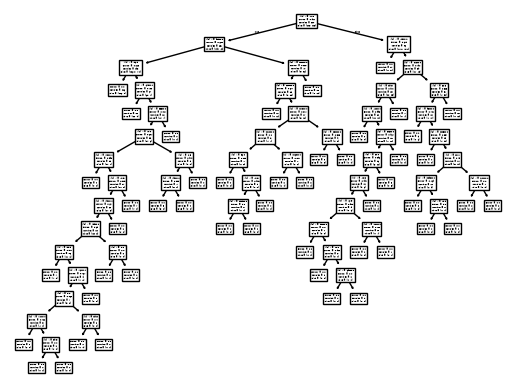

In [65]:
from sklearn import tree
tree.plot_tree(classifier)

Mean: [-2.72797657e-16  1.20538500e-16]
Std: [1. 1.]
Confusion Matrix:
[[64  9]
 [10 37]]
Accuracy: 84.16666666666667 %
Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.88      0.87        73
           1       0.80      0.79      0.80        47

    accuracy                           0.84       120
   macro avg       0.83      0.83      0.83       120
weighted avg       0.84      0.84      0.84       120

The individual is predicted not to purchase


c:\Users\bda\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


[Text(0.49069148936170215, 0.9642857142857143, 'x[0] <= 0.484\ngini = 0.451\nsamples = 280\nvalue = [184, 96]'),
 Text(0.2074468085106383, 0.8928571428571429, 'x[1] <= 0.588\ngini = 0.284\nsamples = 204\nvalue = [169, 35]'),
 Text(0.34906914893617025, 0.9285714285714286, 'True  '),
 Text(0.13829787234042554, 0.8214285714285714, 'x[0] <= -0.106\ngini = 0.078\nsamples = 172\nvalue = [165.0, 7.0]'),
 Text(0.11702127659574468, 0.75, 'gini = 0.0\nsamples = 115\nvalue = [115, 0]'),
 Text(0.1595744680851064, 0.75, 'x[1] <= 0.381\ngini = 0.215\nsamples = 57\nvalue = [50, 7]'),
 Text(0.13829787234042554, 0.6785714285714286, 'x[1] <= -0.091\ngini = 0.191\nsamples = 56\nvalue = [50, 6]'),
 Text(0.11702127659574468, 0.6071428571428571, 'gini = 0.0\nsamples = 27\nvalue = [27, 0]'),
 Text(0.1595744680851064, 0.6071428571428571, 'x[0] <= 0.386\ngini = 0.328\nsamples = 29\nvalue = [23, 6]'),
 Text(0.0851063829787234, 0.5357142857142857, 'x[1] <= -0.003\ngini = 0.278\nsamples = 24\nvalue = [20, 4]'),
 

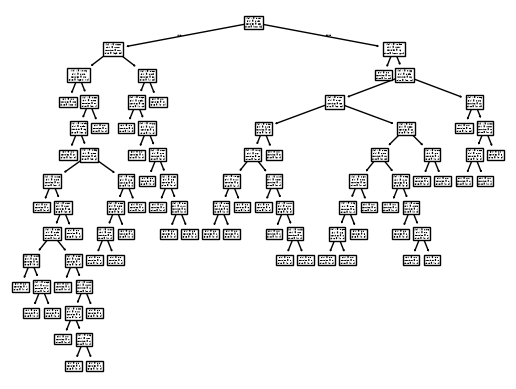

In [104]:
#using gini
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# Load dataset
df = pd.read_csv("Social_Network_Ads.csv")

# Features and target
X = df[["Age", "EstimatedSalary"]]
y = df["Purchased"]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

# Standardization
sc = StandardScaler()

X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

# Check standardization
print("Mean:", X_train.mean(axis=0))
print("Std:", X_train.std(axis=0))

# Create Decision Tree
classifier = DecisionTreeClassifier(
    criterion="gini",
    random_state=0
)

# Train model
classifier.fit(X_train, y_train)

# Predict test data
y_pred = classifier.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy * 100, "%")

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Predict a new individual
new_individual = np.array([[20, 20000]])

# IMPORTANT: use the same scaler
new_individual_scaled = sc.transform(new_individual)

# Make prediction
prediction = classifier.predict(new_individual_scaled)

if prediction[0] == 1:
    print("The individual is predicted to purchase")
else:
    print("The individual is predicted not to purchase")
from sklearn import tree
tree.plot_tree(classifier)


In [ ]:
#gini                  #entropy
test_size              test_size
0.2 = 83.75%           0.2 = 82.5%
0.25 = 83%             0.25 =85%
0.30 = 84.17%          0.30 = 86.7%



In [173]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [174]:
gini_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

entropy_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

gini_model.fit(X_train, y_train)
entropy_model.fit(X_train, y_train)

gini_pred = gini_model.predict(X_test)
entropy_pred = entropy_model.predict(X_test)

print("Gini Accuracy:", accuracy_score(y_test, gini_pred))
print("Entropy Accuracy:", accuracy_score(y_test, entropy_pred))

Gini Accuracy: 0.85
Entropy Accuracy: 0.8375
